# $\zeta(3)+\zeta(5)$: historical recovery

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    zudilin_zeta5_hypergeometric_seeds, zudilin_zeta_sum_readout,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}

target = lambda: arb(3).zeta()+arb(5).zeta()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Zudilin (2002): sum of simultaneous approximants

[Primary paper](https://arxiv.org/pdf/math/0206178).

**CMF:** ${}_8F_7(1)$, rank 7, with 15 parameter axes. All hypergeometric axes are retained.
**Start at source N=2:** (8,3,3,3,3,3,3,3;6,6,6,6,6,6,6). **Direction:** (3,1,1,1,1,1,1,1;2,2,2,2,2,2,2). **Walk depth:** N-2; the diagnostic at source N=500 uses exactly 498 steps.

In [5]:
pair = (3, 5)
cmf = pFq(8, 7, 1)
axes = sp.symbols('x0:8') + sp.symbols('y0:7')
start = dict(zip(axes, [8] + [3] * 7 + [6] * 7))
trajectory = dict(zip(axes, [3] + [1] * 7 + [2] * 7))
seeds = zudilin_zeta5_hypergeometric_seeds()
walks = list(cmf.walk(trajectory, [N - 2 for N in DEPTHS], start))
approximants = [zudilin_zeta_sum_readout(W, N, seeds, pair) for N, W in zip(DEPTHS, walks)]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Zudilin (2002), sum'] = (DEPTHS, deltas)
accuracy['Zudilin (2002), sum'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: -0.280618453497


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

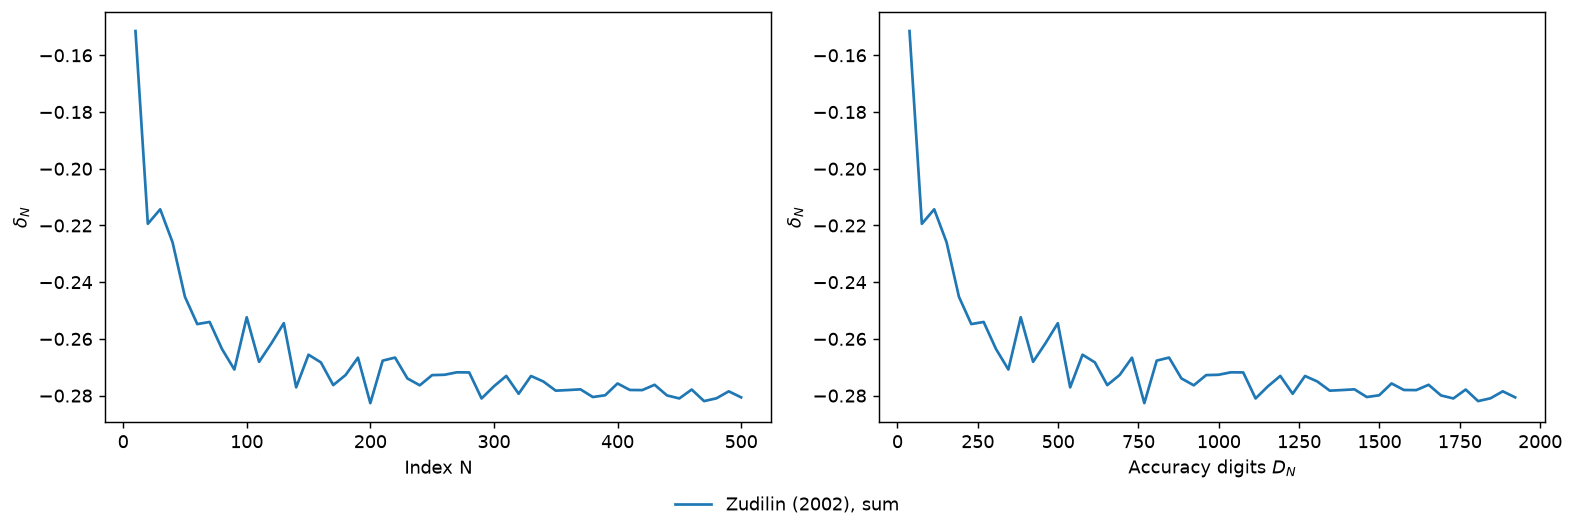

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [9]:
bounds = {
    'Zudilin (2002), sum': 'None stated; component asymptotics imply the error bound above',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Zudilin (2002), sum | None stated; component asymptotics imply the error bound above | -0.280618453497 (N = 500) |